# PCA of first-frame heart shapes

Use one heart per row and flatten **frame 0** into 54,000 XYZ coordinates
(18,000 points × 3). Surface codes and demographics are excluded from PCA.

These are modes of **shape variation between hearts** at the first supplied
frame. To study movement through the cardiac cycle, we would need multiple
frames per heart.

PCA assumes that point `i` corresponds anatomically across hearts and that
coordinates share an aligned reference system.


In [25]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.graph_objects as go
from IPython.display import HTML, display
from sklearn.decomposition import PCA

from introml_myocardial_infarction import CardiacDataLoader

# Locate the project from either the repository or notebooks folder.
project_root = Path.cwd()
if not (project_root / "pyproject.toml").is_file():
    project_root = project_root.parent

data_dir = project_root / "data" / "training_data"
plt.rcParams.update({"figure.figsize": (8, 4), "font.size": 11})


## 1. Load all data, then select coordinates for PCA

`load_all()` returns one DataFrame row per heart, indexed by sample ID.
It contains all demographic columns and a `point_cloud` column holding
each original `(frames, points, 4)` array. Arrays are memory mapped
read-only by default, so every frame is accessible without eagerly
loading the full dataset into RAM.

Here in the notebook, select frame 0, discard the surface-code column,
and flatten XYZ into `X` with shape `(hearts, points * 3)`. Rows follow
`data.index`; each row is ordered `[x0, y0, z0, x1, y1, z1, ...]`.
The loader returns the original data and the analysis chooses its features.


In [26]:
loader = CardiacDataLoader(data_dir)
data = loader.load_all()
demographics = data.drop(columns="point_cloud")
sample_ids = data.index.copy()
frame = 3

if len(data) < 3:
    raise ValueError("Use at least three hearts for this exploration.")

# Select frame 0 and XYZ here, then flatten one heart per matrix row.
X = np.stack([
    cloud[frame, :, :3].reshape(-1)
    for cloud in data["point_cloud"]
])
if not np.isfinite(X).all():
    raise ValueError("The coordinates contain missing or infinite values.")

n_points = X.shape[1] // 3
# Reference codes are for colouring only; they are not PCA features.
surface_codes = data["point_cloud"].iloc[0][frame, :, 3].copy()
print(f"X: {X.shape[0]} hearts × {X.shape[1]} coordinates")
print(f"Matrix memory: {X.nbytes / 1e6:.1f} MB")
demographics.head()
X


X: 900 hearts × 54000 coordinates
Matrix memory: 388.8 MB


array([[-17.53883934,  14.00244427,   9.49431133, ..., -14.42399406,
        -31.48902702,  49.87114716],
       [-13.44630051,   5.72303009,   9.70984745, ..., -12.61193943,
        -35.12165451,  49.5970726 ],
       [ -9.14038944,  16.98768044,   9.3844862 , ...,  -9.74003029,
        -27.05115891,  43.25251389],
       ...,
       [-17.61471176,  11.35139942,  10.86362457, ..., -16.67416763,
        -31.22364044,  49.21348953],
       [-10.88890934,  13.47105885,   8.63877964, ..., -13.59295082,
        -32.26075745,  42.1778717 ],
       [-10.0791198 ,  27.74601814,  15.25697926, ...,   1.57591303,
         -8.35131463,  44.48336079]], shape=(900, 54000))

## 2. Fit PCA

[scikit-learn PCA](https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html)
centres each coordinate across hearts. We keep the original coordinate scale
and do not whiten scores.

Start with the leading 20 components. The randomized SVD solver approximates
these components efficiently, with a fixed seed for repeatability. Change
`requested_components` to explore more modes. For an exact decomposition,
set `svd_solver="full"` (this is slower for this wide matrix).


In [27]:
requested_components = 20
n_components = min(requested_components, X.shape[0] - 1, X.shape[1])
pca = PCA(n_components=n_components, svd_solver="randomized", random_state=42)
scores = pca.fit_transform(X)

pc_names = [f"PC{i + 1}" for i in range(n_components)]
scores_df = pd.DataFrame(scores, index=sample_ids, columns=pc_names)
scores_df.index.name = "sample_id"
mean_shape = pca.mean_.reshape(n_points, 3)
modes = pca.components_.reshape(n_components, n_points, 3)
mode_std = np.sqrt(pca.explained_variance_)

print(f"Retained {n_components} components")
print(f"Explained variance: {pca.explained_variance_ratio_.sum():.1%}")
scores_df.head()


Retained 20 components
Explained variance: 89.4%


,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,PC11,PC12,PC13,PC14,PC15,PC16,PC17,PC18,PC19,PC20
sample_id,,,,,,,,,,,,,,,,,,,,
0,653.733223,-723.264200,556.175938,-142.971783,84.143537,271.174460,-23.653982,137.756300,85.500836,31.322954,14.917365,7.518418,0.884062,-0.661925,1.157491,0.685901,2.497963,-9.425828,-7.081326,-5.941867
1,-12.799703,-655.164386,-231.541949,78.633667,177.614183,-90.903430,48.985864,19.458536,29.846381,-0.798707,-3.178775,1.621629,-1.476851,-10.695034,2.489556,-1.460457,2.318900,-2.035321,-2.727661,-10.540458
2,429.831762,391.324995,89.704884,-243.133390,-67.461454,-40.056105,86.950764,163.898584,-20.705381,-51.137585,-15.516961,2.825351,-4.307957,1.653883,-1.986873,3.242685,-3.871334,-5.358683,1.514920,-6.158272
3,298.570041,-919.390651,-374.443814,107.336413,217.315730,-431.947403,28.265054,282.015844,8.499951,144.511108,-10.705360,11.530695,-11.210158,-5.602988,-7.226496,-0.755945,-6.228026,25.994087,-3.860390,5.898112
4,6.934325,807.175753,544.236680,-185.116894,9.097630,83.166174,3.361555,-71.802507,-36.743084,-20.679624,2.063359,1.516328,4.254866,5.873261,-1.811808,-0.555795,-4.395053,-5.464342,-1.473022,2.682791


## 3. How much variation do the modes explain?

Individual bars show each retained mode's fraction of total coordinate variance.
The cumulative curve covers the retained components only; it may stop below
100%. Increase the number fitted if you want to capture more variance.


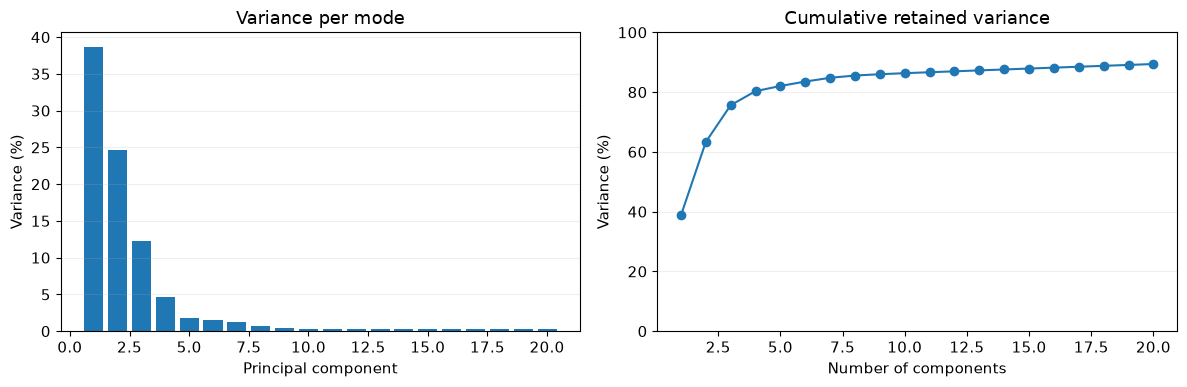

,variance_fraction,cumulative_fraction,score_std
component,,,
PC1,0.387128,0.387128,705.483278
PC2,0.245863,0.632991,562.219824
PC3,0.123183,0.756174,397.955898
PC4,0.046967,0.803140,245.727622
PC5,0.017329,0.820469,149.260357
PC6,0.014820,0.835289,138.032036
PC7,0.012582,0.847871,127.186441
PC8,0.007578,0.855449,98.702970
PC9,0.004350,0.859798,74.780003


In [28]:
variance_table = pd.DataFrame({
    "variance_fraction": pca.explained_variance_ratio_,
    "cumulative_fraction": np.cumsum(pca.explained_variance_ratio_),
    "score_std": mode_std,
}, index=pd.Index(pc_names, name="component"))

component_numbers = np.arange(1, n_components + 1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(component_numbers, 100 * variance_table["variance_fraction"])
axes[0].set(title="Variance per mode", xlabel="Principal component", ylabel="Variance (%)")
axes[1].plot(component_numbers, 100 * variance_table["cumulative_fraction"], marker="o")
axes[1].set(title="Cumulative retained variance", xlabel="Number of components", ylabel="Variance (%)", ylim=(0, 100))
for ax in axes:
    ax.grid(axis="y", alpha=0.2)
fig.tight_layout()
plt.show()
variance_table


## 4. Locate each heart in PCA space

A score describes how far a heart lies along a mode. Colours show the existing
MI labels after fitting: the labels are not used to learn the components.
This plot describes the training samples and does not measure prediction accuracy.


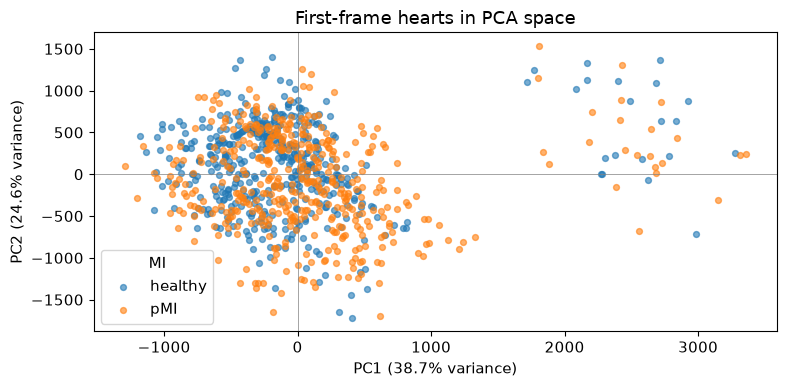

In [29]:
fig, ax = plt.subplots()
for label, group in scores_df.join(demographics[["MI"]]).groupby("MI"):
    ax.scatter(group["PC1"], group["PC2"], s=18, alpha=0.6, label=label)
ax.set(
    title="First-frame hearts in PCA space",
    xlabel=f"PC1 ({pca.explained_variance_ratio_[0]:.1%} variance)",
    ylabel=f"PC2 ({pca.explained_variance_ratio_[1]:.1%} variance)",
)
ax.axhline(0, color="grey", lw=0.5)
ax.axvline(0, color="grey", lw=0.5)
ax.legend(title="MI")
fig.tight_layout()
plt.show()


## 5. Compare pairs of principal components

Scatter plots show pairs of PCA scores, coloured by the stored MI labels:
**healthy = no MI**, **pMI = MI**. Diagonal panels show each group's score
distribution using the same histogram bins. Change `pcs_to_plot` to
explore a different selection of components.


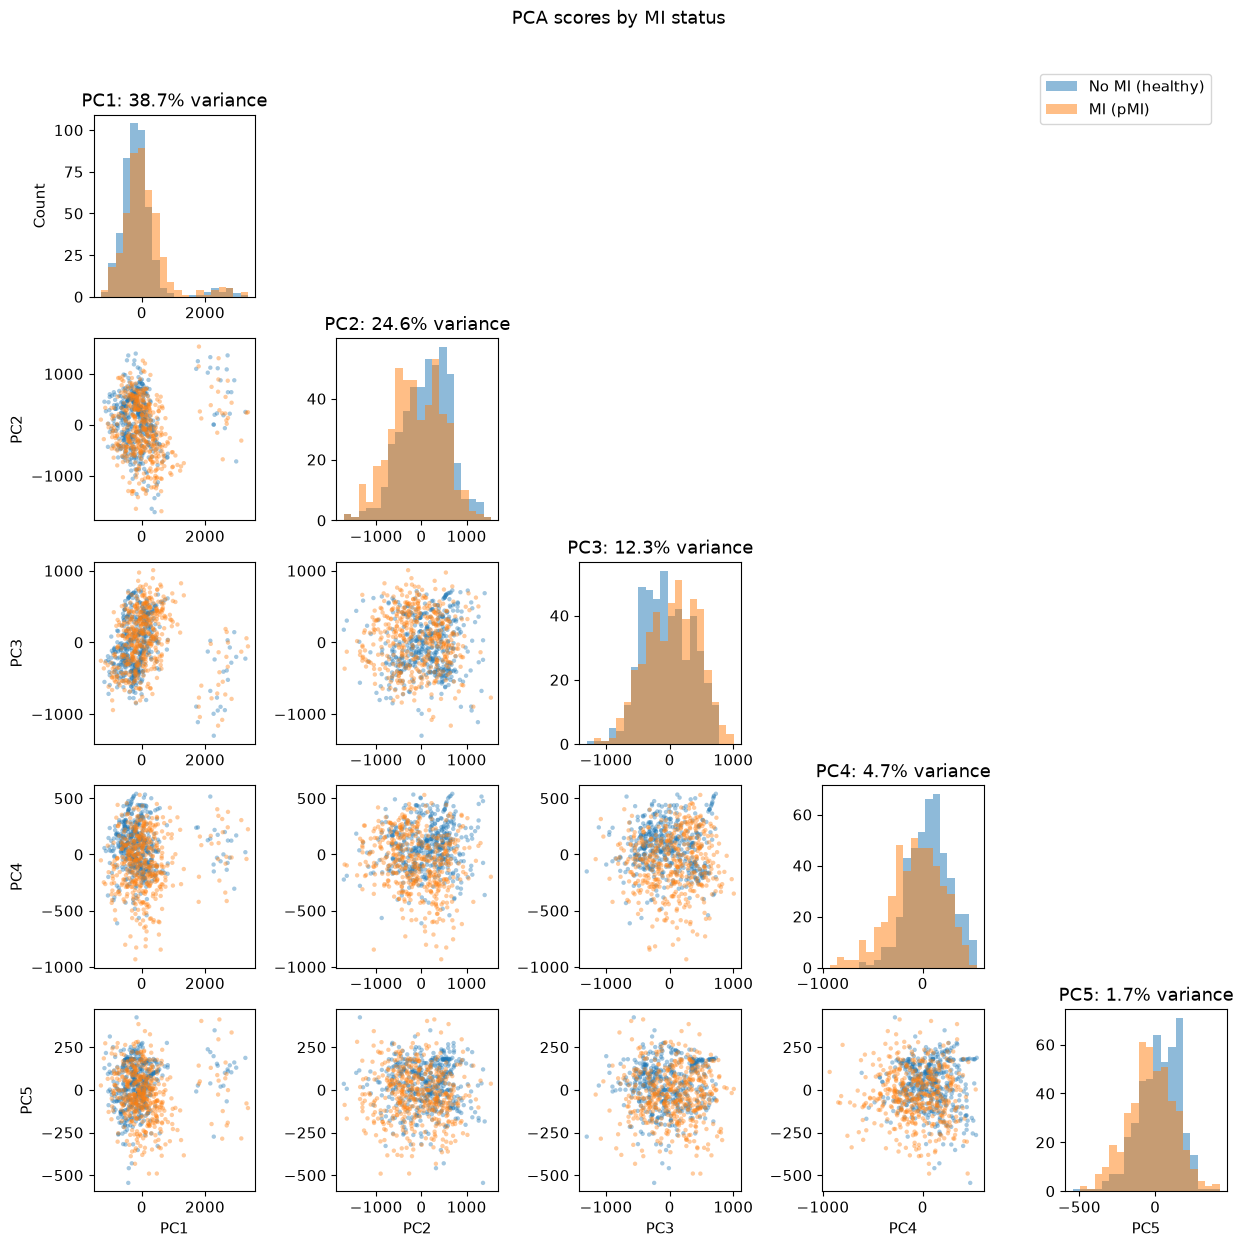

In [30]:
pcs_to_plot = list(scores_df.columns[:5])  # For example: ["PC1", "PC3", "PC6"].
pair_data = scores_df[pcs_to_plot].join(demographics[["MI"]])
group_styles = {
    "healthy": ("No MI (healthy)", "tab:blue"),
    "pMI": ("MI (pMI)", "tab:orange"),
}

n_pcs = len(pcs_to_plot)
fig, axes = plt.subplots(n_pcs, n_pcs, figsize=(2.5 * n_pcs, 2.5 * n_pcs), squeeze=False)
for row, y_pc in enumerate(pcs_to_plot):
    for col, x_pc in enumerate(pcs_to_plot):
        ax = axes[row, col]
        if col > row:
            ax.set_visible(False)
            continue
        if row == col:
            bins = np.histogram_bin_edges(pair_data[x_pc], bins=20)
        for stored_label, (label, color) in group_styles.items():
            group = pair_data.loc[pair_data["MI"] == stored_label]
            if row == col:
                ax.hist(group[x_pc], bins=bins, color=color, alpha=0.5, label=label)
            else:
                ax.scatter(group[x_pc], group[y_pc], s=10, alpha=0.4,
                           color=color, label=label, edgecolors="none")
        if row == n_pcs - 1:
            ax.set_xlabel(x_pc)
        if col == 0:
            ax.set_ylabel("Count" if row == col else y_pc)
        if row == col:
            component_index = scores_df.columns.get_loc(x_pc)
            ax.set_title(f"{x_pc}: {pca.explained_variance_ratio_[component_index]:.1%} variance")

handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper right", bbox_to_anchor=(0.98, 0.95))
fig.suptitle("PCA scores by MI status", y=0.995)
fig.tight_layout(rect=(0, 0, 1, 0.97))
plt.show()


## 6. Identify samples with extreme PCA scores

Use the same `pcs_to_plot` as the pair plot. For each PC, list the three
samples furthest from its mean score, considering both positive and
negative extremes. `z_score` expresses that distance in standard
deviations, so the different PCs can be compared.

The second table counts how often each sample appears among those
extremes. `most_extreme_count` counts rank-1 appearances; `top_pc_count`
counts appearances in the top three. Repeated sample IDs show whether
the same heart is extreme across several PCs. These rankings identify
candidates for inspection and do not automatically establish bad data.


In [24]:
top_n = 3  # Number of extreme samples to list for each plotted PC.
pc_scores = scores_df[pcs_to_plot]
score_std = pc_scores.std(ddof=1).replace(0, np.nan)
z_scores = (pc_scores - pc_scores.mean()) / score_std

extreme_rows = []
for pc in pcs_to_plot:
    # Absolute values include both tails; retain the signed score below.
    extreme_ids = z_scores[pc].abs().dropna().nlargest(top_n).index
    for rank, sample_id in enumerate(extreme_ids, start=1):
        extreme_rows.append({
            "component": pc,
            "rank": rank,
            "sample_id": sample_id,
            "score": scores_df.loc[sample_id, pc],
            "z_score": z_scores.loc[sample_id, pc],
            "abs_z": abs(z_scores.loc[sample_id, pc]),
            "MI": demographics.loc[sample_id, "MI"],
        })

extreme_scores = pd.DataFrame(extreme_rows)
if extreme_scores.empty:
    print("No varying components are available to rank.")
else:
    print(f"Top {top_n} extreme samples per PC (rank 1 is the most extreme):")
    display(extreme_scores.drop(columns="abs_z").round(3))

    recurring_samples = extreme_scores.groupby("sample_id").agg(
        top_pc_count=("component", "nunique"),
        components=("component", lambda values: ", ".join(values)),
        most_extreme_count=("rank", lambda ranks: (ranks == 1).sum()),
        largest_abs_z=("abs_z", "max"),
    ).join(demographics)
    recurring_samples = recurring_samples.sort_values(
        ["most_extreme_count", "top_pc_count", "largest_abs_z"],
        ascending=False,
    )
    print("Sample IDs recurring across PCs, with their demographics:")
    display(recurring_samples.round(3))


Top 3 extreme samples per PC (rank 1 is the most extreme):


,component,rank,sample_id,score,z_score,MI
0,PC1,1,658,7701.874,10.280,healthy
1,PC1,2,591,3480.167,4.645,pMI
2,PC1,3,573,3404.613,4.544,healthy
3,PC2,1,658,-2185.491,-3.684,healthy
4,PC2,2,266,1882.914,3.174,pMI
5,PC2,3,256,1841.067,3.103,healthy
6,PC3,1,658,1744.434,4.278,healthy
7,PC3,2,872,1582.785,3.882,pMI
8,PC3,3,666,1492.779,3.661,healthy
9,PC4,1,337,-901.879,-3.296,pMI


Sample IDs recurring across PCs, with their demographics:


,top_pc_count,components,most_extreme_count,largest_abs_z,MI,age,BMI,height,weight,diastolic_BP,systolic_BP,sex
sample_id,,,,,,,,,,,,
658,4,"PC1, PC2, PC3, PC5",4,16.653,healthy,60.455,25.521,167.421,70.118,78.592,136.428,False
337,1,PC4,1,3.296,pMI,67.126,29.736,177.039,91.914,76.899,141.221,True
591,1,PC1,0,4.645,pMI,64.108,30.473,172.378,89.691,80.175,142.563,True
573,1,PC1,0,4.544,healthy,65.325,28.565,168.255,80.574,79.386,139.473,True
872,1,PC3,0,3.882,pMI,68.272,28.583,170.392,82.933,76.923,135.273,True
666,1,PC3,0,3.661,healthy,61.709,24.715,177.173,77.890,76.453,130.325,True
375,1,PC5,0,3.549,pMI,68.332,28.279,176.820,88.013,77.375,138.631,True
266,1,PC2,0,3.174,pMI,63.366,26.095,171.994,77.005,76.278,136.486,True
356,1,PC4,0,3.141,pMI,65.024,25.299,168.670,71.858,75.747,139.647,True
